# 13 双目深度：左右图 → 视差矩阵 → 米制深度

用可复现的纹理平面生成一对已经极线校正的图片，运行真实 StereoSGBM 匹配。
已知焦距与基线才可以把视差换成米制深度；单张照片并不能直接套用该公式。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cuda


## 1. 输入：具有已知位移的左右图

世界是一个深度为 2 m 的平面，焦距 240 px，双目基线 0.1 m，所以真实视差为 12 px。
右图中同一点比左图向左 12 px；边界产生无法匹配的区域。


真实视差: 12 px
左图局部矩阵:
 [[135 100  80  77  71  92]
 [100 109  86  60 116 137]
 [176 198 174 114  65  66]
 [168 176 158 146  75  75]]
右图对应局部矩阵:
 [[135 100  80  77  71  92]
 [100 109  86  60 116 137]
 [176 198 174 114  65  66]
 [168 176 158 146  75  75]]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 24038 (\N{CJK UNIFIED IDEOGRAPH-5DE6}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21491 (\N{CJK UNIFIED IDEOGRAPH-53F3}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24038 (\N{CJK UNIFIED IDEOGRAPH-5DE6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylab

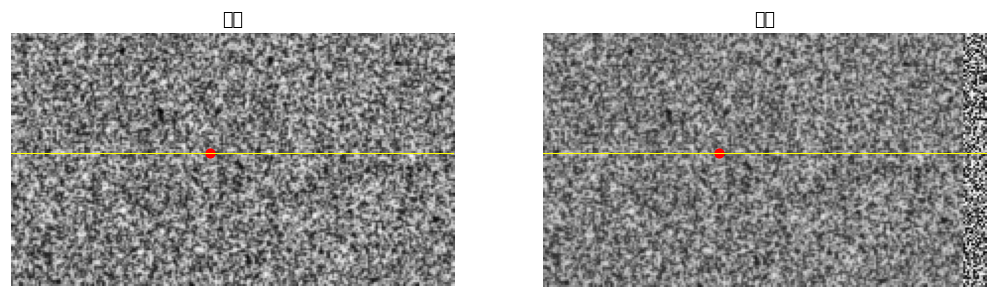

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/13_depth_inputs.png')

In [2]:
rng = np.random.default_rng(42)
height, width = 128, 224
texture = rng.integers(0, 256, (height, width), dtype=np.uint8)
left = cv2.GaussianBlur(texture, (3, 3), .6)
focal_px, baseline_m, true_depth_m = 240., .1, 2.
d_true = int(focal_px*baseline_m/true_depth_m)
right = rng.integers(0, 256, left.shape, dtype=np.uint8)
right[:, :-d_true] = left[:, d_true:]
print("真实视差:", d_true, "px")
print("左图局部矩阵:\n", left[60:64, 100:106])
print("右图对应局部矩阵:\n", right[60:64, 100-d_true:106-d_true])
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, im, title, x in zip(axs, [left, right], ["左图", "右图"], [100,100-d_true]):
    ax.imshow(im, cmap="gray"); ax.scatter([x], [60], c="red"); ax.axhline(60,c="yellow",lw=.7); ax.set_title(title); ax.axis("off")
save_figure("13_depth_inputs")


## 2. 匹配视差

StereoSGBM 综合局部匹配代价与平滑约束。`numDisparities` 必须是 16 的倍数；`blockSize` 取奇数。
OpenCV 返回有符号定点值，需要除以 16 才得到像素视差。非正视差视为无效。

矩阵怎么读：左图、右图和视差图都是 `[128,224]`，相同的行列索引指向左相机的对应像素。原始值 192 除以 16 得到 12 px；再计算 `240×0.1/12=2 m`。深度图中的 NaN 表示当前没有有效估计，不表示物体距离为零。


In [3]:
matcher = cv2.StereoSGBM_create(minDisparity=0, numDisparities=32, blockSize=5,
                               P1=8*5**2, P2=32*5**2, uniquenessRatio=8,
                               speckleWindowSize=0, disp12MaxDiff=1)
raw = matcher.compute(left, right)
disparity = raw.astype(np.float32)/16.
valid = disparity > 0
evaluation_mask = valid.copy()
evaluation_mask[:, :40] = False
evaluation_mask[:, -20:] = False
evaluation_mask[:10] = False; evaluation_mask[-10:] = False
print("原始定点值 4×6:\n", raw[60:64, 100:106])
print("视差 px 4×6:\n", disparity[60:64, 100:106])
print("中央区域有效率:", evaluation_mask.sum()/((width-60)*(height-20)))


原始定点值 4×6:
 [[192 192 192 192 192 192]
 [192 192 192 192 192 192]
 [192 192 192 192 192 192]
 [192 192 192 192 192 192]]
视差 px 4×6:
 [[12. 12. 12. 12. 12. 12.]
 [12. 12. 12. 12. 12. 12.]
 [12. 12. 12. 12. 12. 12.]
 [12. 12. 12. 12. 12. 12.]]
中央区域有效率: 1.0


## 3. 视差转深度

校正后的理想双目几何：$d=x_L-x_R$，$Z=fB/d$。
$f$ 单位为像素，$B$ 单位为米，则 $Z$ 为米。无效值用 NaN，而不是当作 0 m。


中央有效像素视差 MAE=0.0000 px
中央有效像素深度 MAE=0.0000 m
深度局部矩阵 m:
 [[2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2. 2.]]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21305 (\N{CJK UNIFIED IDEOGRAPH-5339}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 37197 (\N{CJK UNIFIED IDEOGRAPH-914D}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 35270 (\N{CJK UNIFIED IDEOGR

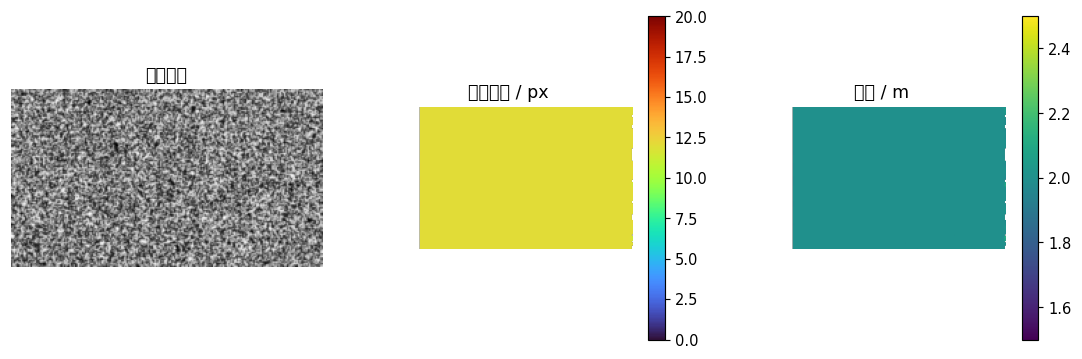

In [4]:
depth = np.full(disparity.shape, np.nan, np.float32)
depth[valid] = focal_px*baseline_m/disparity[valid]
disparity_mae = np.mean(np.abs(disparity[evaluation_mask]-d_true))
depth_mae = np.mean(np.abs(depth[evaluation_mask]-true_depth_m))
print(f"中央有效像素视差 MAE={disparity_mae:.4f} px")
print(f"中央有效像素深度 MAE={depth_mae:.4f} m")
print("深度局部矩阵 m:\n", np.round(depth[60:64,100:106],3))
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
axs[0].imshow(left,cmap="gray"); axs[0].set_title("输入左图")
p = axs[1].imshow(np.where(valid,disparity,np.nan),cmap="turbo",vmin=0,vmax=20); axs[1].set_title("匹配视差 / px"); fig.colorbar(p,ax=axs[1])
p = axs[2].imshow(depth,cmap="viridis",vmin=1.5,vmax=2.5); axs[2].set_title("深度 / m"); fig.colorbar(p,ax=axs[2])
for ax in axs: ax.axis("off")
save_figure("13_depth_outputs")
assert evaluation_mask.any() and np.isfinite(depth[evaluation_mask]).all()


## 4. 误差传播与失败条件

同样 1 px 视差误差对远处深度影响更大。纹理不足、重复图案、遮挡、反光、未校正左右图都会造成错误匹配。
本课只验证一个有纹理的平面，不能据此宣称复杂场景都能达到相同误差。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 30830 (\N{CJK UNIFIED IDEOGRAPH-786E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


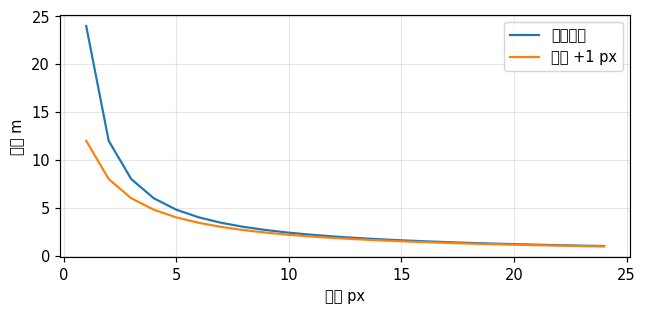

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/13_depth_sensitivity.png')

In [5]:
ds = np.arange(1, 25, dtype=float)
z = focal_px*baseline_m/ds
z_perturbed = focal_px*baseline_m/(ds+1)
plt.figure(figsize=(7, 3)); plt.plot(ds,z,label="正确视差"); plt.plot(ds,z_perturbed,label="视差 +1 px")
plt.xlabel("视差 px"); plt.ylabel("深度 m"); plt.legend(); plt.grid(alpha=.3)
save_figure("13_depth_sensitivity")


## 5. 学生练习与真实双目扩展

将纹理换成纯灰色，比较无效率；把位移改为 6 px，先预测深度再运行。
真实双目需要相机标定、畸变校正、极线校正和相机参数文件，不能仅把任意两张图片代入。

来源：[OpenCV 双目深度教程](https://docs.opencv.org/4.x/dd/d53/tutorial_py_depthmap.html)、[StereoSGBM 参数](https://docs.opencv.org/4.x/d2/d85/classcv_1_1StereoSGBM.html)。
